# 02 — Camera laboratory: pixels, lies, and geometry

A camera is not a transparent window. It samples light through colored filters, adjusts its own settings, moves a finite amount of data, projects 3D geometry onto a 2D sensor, and bends straight lines when the lens feels adventurous.

This notebook uses a synthetic scene so we can break the camera deliberately and know what the undamaged world looked like. We will explore:

- Bayer RGB filters and demosaicing;
- resolution, FPS, and bandwidth;
- exposure, gain, white balance, and focus;
- rolling versus global shutter;
- focal length, field of view, and the camera matrix;
- radial distortion and calibration;
- distance estimation from a known object size.

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

np.set_printoptions(precision=2, suppress=True)
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")

OpenCV 4.14.0 | NumPy 2.5.4


## 1. Build something for the camera to misunderstand

The scene contains saturated colors, neutral patches, thin lines, text, and a grid. Different camera failures will attack different parts of it.

> **What is a saturated color?** A highly saturated color looks strong and vivid—think tomato red instead of dusty pink. Low saturation moves toward gray, while brightness is a separate question: a dark red can still be strongly saturated. In HSV terms, this is the **S**.
>
> Camera people also say a sensor pixel is **saturated** when it received more light than it can represent and got clipped to its maximum value. Same word, different trouble: one means vivid color; the other means the pixel's light bucket overflowed.

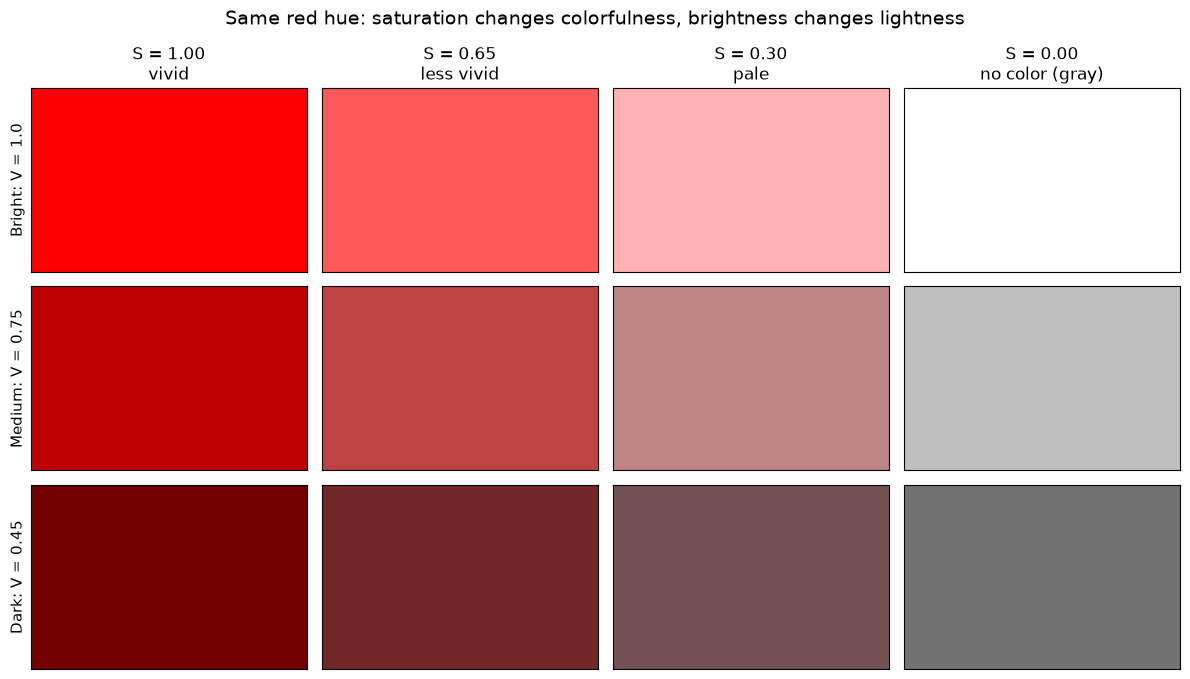

In [10]:
saturation_levels = [1.0, 0.65, 0.30, 0.0]
brightness_levels = [(1.0, "Bright: V = 1.0"), (0.75, "Medium: V = 0.75"), (0.45, "Dark: V = 0.45")]
column_names = ["vivid", "less vivid", "pale", "no color (gray)"]

fig, axes = plt.subplots(3, 4, figsize=(12, 7))
for row, (value, row_name) in enumerate(brightness_levels):
    for col, (saturation, column_name) in enumerate(zip(saturation_levels, column_names)):
        # Fixed red hue: saturation controls how much gray is mixed in; value controls brightness.
        rgb = np.array([value, value * (1 - saturation), value * (1 - saturation)])
        patch = np.ones((80, 120, 3)) * rgb
        axes[row, col].imshow(patch)
        if row == 0:
            axes[row, col].set_title(f"S = {saturation:.2f}\n{column_name}")
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(row_name, fontsize=11)

fig.suptitle("Same red hue: saturation changes colorfulness, brightness changes lightness", fontsize=14)
plt.tight_layout()
plt.show()

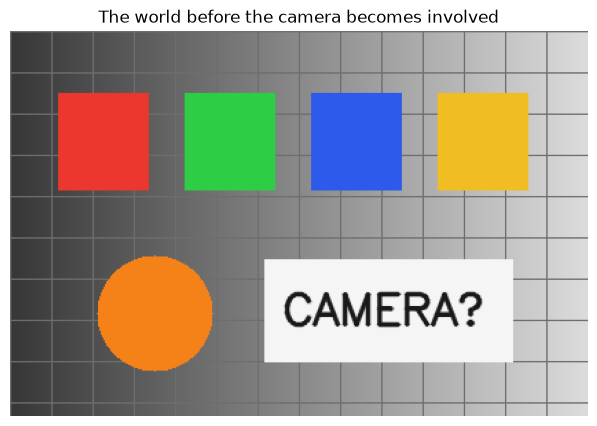

In [13]:
def make_camera_scene(height=280, width=420):
    image = np.full((height, width, 3), 225, dtype=np.uint8)
    image[:] = np.linspace(55, 220, width, dtype=np.uint8)[None, :, None]

    for x in range(0, width, 30):
        cv2.line(image, (x, 0), (x, height - 1), (110, 110, 110), 1)
    for y in range(0, height, 30):
        cv2.line(image, (0, y), (width - 1, y), (110, 110, 110), 1)

    colors = [(235, 55, 45), (45, 205, 70), (45, 90, 235), (240, 190, 35)]
    for index, color in enumerate(colors):
        x0 = 35 + index * 92
        cv2.rectangle(image, (x0, 45), (x0 + 65, 115), color, -1)

    cv2.circle(image, (105, 205), 42, (245, 130, 25), -1)
    cv2.rectangle(image, (185, 166), (365, 240), (245, 245, 245), -1)
    cv2.putText(image, "CAMERA?", (198, 213), cv2.FONT_HERSHEY_SIMPLEX, 1.05, (25, 25, 25), 2, cv2.LINE_AA)
    return image

scene = make_camera_scene()
plt.figure(figsize=(11, 5))
plt.imshow(scene)
plt.title("The world before the camera becomes involved")
plt.axis("off")
plt.show()

## 2. Why are there RGB filters on the sensor?

> **Demosaicing, before the name scares us:** each sensor location sees only red, green, or blue. Demosaicing simply asks nearby locations for clues and estimates the two missing colors, producing a full `[R, G, B]` pixel. In short: **de-mosaic-ing** turns the color mosaic into a normal image. The demon mostly does neighborly guesswork. 👹

A photosensitive element mainly measures how much light arrived; it does not automatically know the color. Many cameras place a repeating mosaic of red, green, and blue filters over the sensor. A common **RGGB Bayer pattern** contains twice as many green samples because luminance detail and human visual sensitivity are strongly represented there.

> **OpenCV naming trap:** a Bayer conversion constant hides two choices: **which mosaic orientation entered** and **which channel order should leave**. The sensor tile can be RGGB, BGGR, GRBG, or GBRG; choosing the wrong one can swap red and blue or create strange colors. The final `RGB` in `cv2.COLOR_BayerBG2RGB` requests RGB output (OpenCV often uses BGR elsewhere).
>
> Our manually built tile begins `R G / G B`, usually described as **RGGB**, yet the matching OpenCV constant is `COLOR_BayerBG2RGB`. OpenCV's short two-letter Bayer names follow a convention that looks reversed relative to the common top-left tile name. This is normal, confusing, and an excellent reason to test with known red and blue patches instead of trusting your dignity.

Each sensor location therefore measures one color, not a complete RGB triplet. **Demosaicing** estimates the two missing colors from neighboring samples. The camera manufactures a full-color pixel from incomplete local evidence—politely, this is called interpolation.

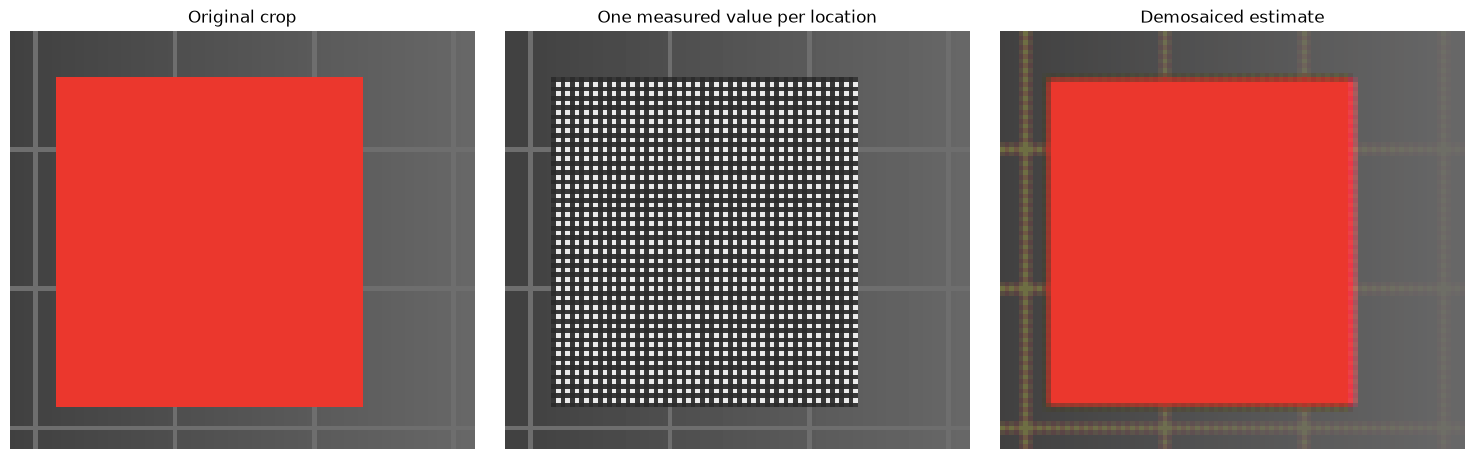

In [14]:
def sample_rggb(rgb):
    raw = np.zeros(rgb.shape[:2], dtype=np.uint8)
    raw[0::2, 0::2] = rgb[0::2, 0::2, 0]  # Red
    raw[0::2, 1::2] = rgb[0::2, 1::2, 1]  # Green
    raw[1::2, 0::2] = rgb[1::2, 0::2, 1]  # Green
    raw[1::2, 1::2] = rgb[1::2, 1::2, 2]  # Blue
    return raw

raw_bayer = sample_rggb(scene)
demosaiced = cv2.cvtColor(raw_bayer, cv2.COLOR_BayerBG2RGB)
crop = np.s_[35:125, 25:125]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(scene[crop])
axes[0].set_title("Original crop")
axes[1].imshow(raw_bayer[crop], cmap="gray", vmin=0, vmax=255)
axes[1].set_title("One measured value per location")
axes[2].imshow(demosaiced[crop])
axes[2].set_title("Demosaiced estimate")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

> **What is the black net in the middle image?** We displayed the one-channel raw Bayer measurements as grayscale so every sensor value is visible. Over the red rectangle, red-filtered locations measure a large value and look white, while neighboring green- and blue-filtered locations measure little and look dark. Their repeating arrangement creates the net—it is not present in the scene and is not a camera defect. Demosaicing uses the known filter positions to interpret those measurements as color.

> **Off-topic, but useful — can pixels shrink forever?**
>
> No. Smaller sensor elements collect fewer photons and tend to become noisier. Optics also cannot resolve unlimited detail: diffraction depends on wavelength and aperture. Eventually more pixels merely create a more detailed description of blur. The megapixel department prefers that we phrase this quietly.

## 3. Resolution × FPS: the data pipe notices

Full HD means `1920 × 1080` pixels. FPS means frames per second. For uncompressed 8-bit RGB, a rough bandwidth estimate is:

`width × height × 3 bytes × FPS`

Real cameras may use raw mosaics, compression, chroma subsampling, or other formats, but this estimate makes the trade-off visible.

With a 300 MB/s budget:
  720p @ 30: needs 30 FPS | link allows about 108.5 FPS → enough ✓
  1080p @ 30: needs 30 FPS | link allows about 48.2 FPS → enough ✓
  1080p @ 60: needs 60 FPS | link allows about 48.2 FPS → NOT ENOUGH ✗ (short by 11.8 FPS)
  4K @ 30: needs 30 FPS | link allows about 12.1 FPS → NOT ENOUGH ✗ (short by 17.9 FPS)
  4K @ 60: needs 60 FPS | link allows about 12.1 FPS → NOT ENOUGH ✗ (short by 47.9 FPS)


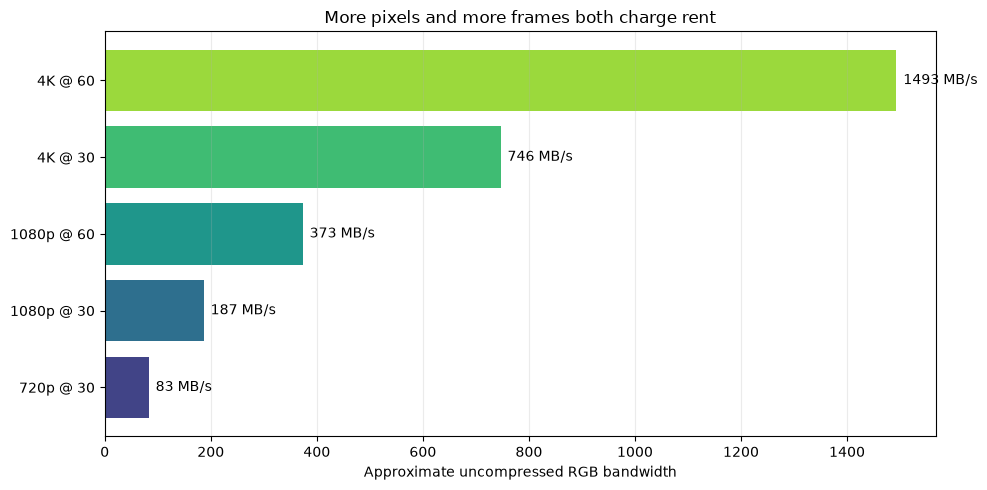

In [18]:
video_modes = {
    "720p @ 30": (1280, 720, 30),
    "1080p @ 30": (1920, 1080, 30),
    "1080p @ 60": (1920, 1080, 60),
    "4K @ 30": (3840, 2160, 30),
    "4K @ 60": (3840, 2160, 60),
}

bandwidth_mb_s = {
    name: width * height * 3 * fps / 1_000_000
    for name, (width, height, fps) in video_modes.items()
}

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(list(bandwidth_mb_s), list(bandwidth_mb_s.values()), color=plt.cm.viridis(np.linspace(0.2, 0.85, len(video_modes))))
ax.bar_label(bars, fmt="%.0f MB/s", padding=5)
ax.set_xlabel("Approximate uncompressed RGB bandwidth")
ax.set_title("More pixels and more frames both charge rent")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()

bandwidth_budget = 300  # MB/s, an imaginary camera-to-computer link
print(f"With a {bandwidth_budget} MB/s budget:")
for label, (width, height, required_fps) in video_modes.items():
    max_fps = bandwidth_budget * 1_000_000 / (width * height * 3)
    status = "enough ✓" if max_fps >= required_fps else f"NOT ENOUGH ✗ (short by {required_fps - max_fps:.1f} FPS)"
    print(f"  {label}: needs {required_fps} FPS | link allows about {max_fps:.1f} FPS → {status}")

## 4. Camera settings: four knobs, four different disasters

- **Exposure time** controls how long light is collected. Longer exposure brightens the image but can blur motion.
- **Gain** amplifies the measured signal after capture. It brightens the image and also amplifies noise.
- **White balance** scales color channels to make neutral objects look neutral under different lighting. Wrong values create a color cast.
- **Focus** determines which distances form sharp images. Bad focus destroys high-frequency detail.

Automatic adjustment is useful for pleasant video. For measurement pipelines, changing parameters can move thresholds and apparent features between frames. Locking them makes experiments reproducible.

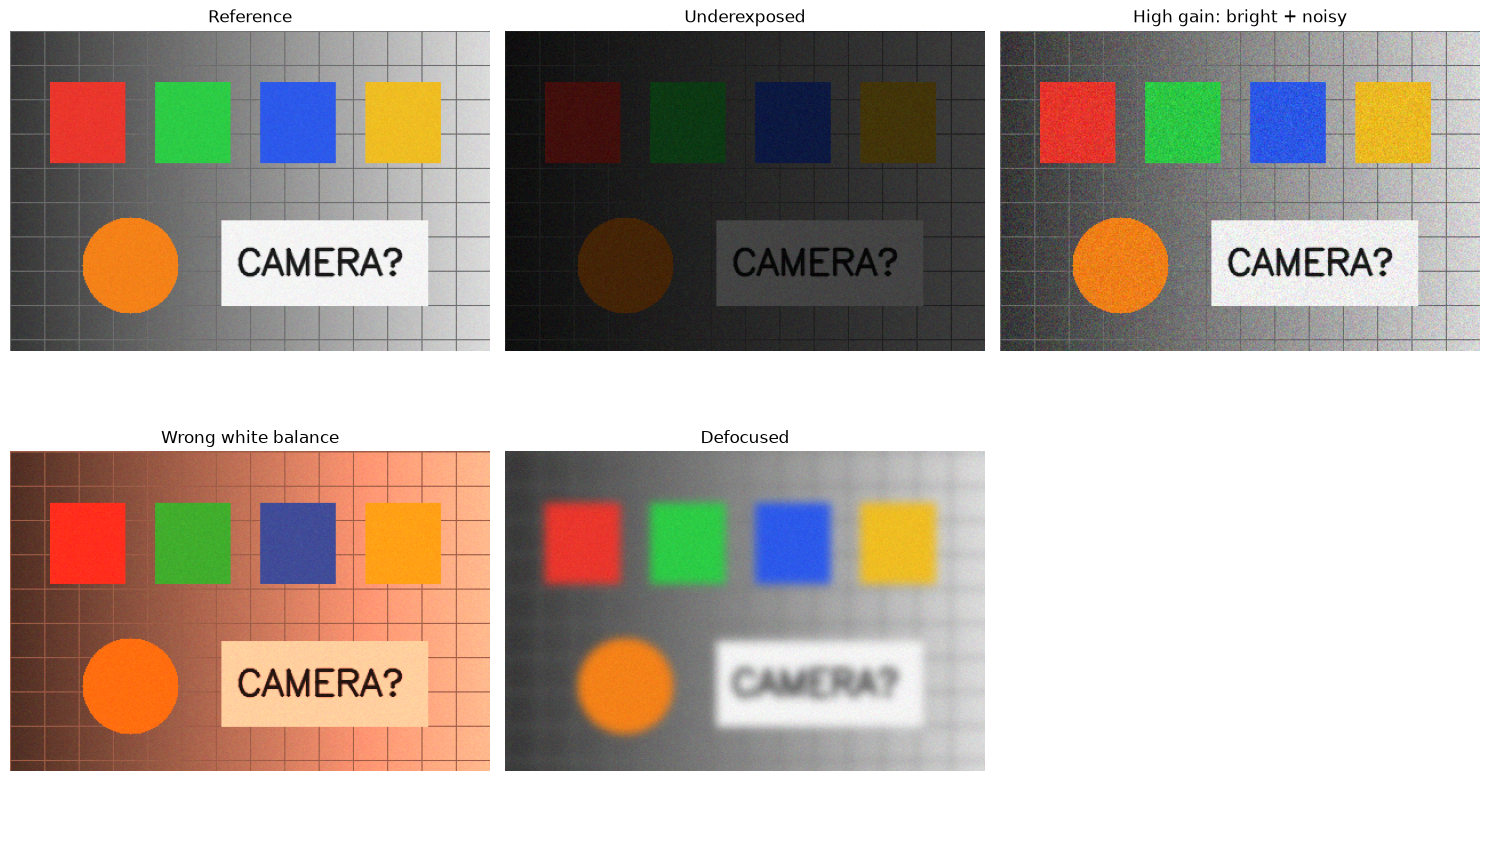

In [20]:
def simulate_camera(rgb, exposure=1.0, gain=1.0, white_balance=(1.0, 1.0, 1.0), focus_sigma=0.0, seed=4):
    rng = np.random.default_rng(seed)
    optical_image = rgb.astype(np.float32) / 255
    if focus_sigma > 0:
        optical_image = cv2.GaussianBlur(optical_image, (0, 0), focus_sigma)

    signal = optical_image * exposure * np.asarray(white_balance)[None, None, :]
    sensor_noise = rng.normal(0, 0.018, signal.shape)
    measured = (signal + sensor_noise) * gain
    return np.clip(measured * 255, 0, 255).astype(np.uint8)

camera_failures = {
    "Reference": dict(),
    "Underexposed": dict(exposure=0.28),
    "High gain: bright + noisy": dict(exposure=0.35, gain=2.8),
    "Wrong white balance": dict(white_balance=(1.45, 0.85, 0.65)),
    "Defocused": dict(focus_sigma=4.0),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, parameters) in zip(axes.flat, camera_failures.items()):
    result = simulate_camera(scene, **parameters)
    ax.imshow(result)
    ax.set_title(name)
    ax.axis("off")
axes.flat[-1].axis("off")
plt.tight_layout()

### Practice: become an unhelpful camera

Change one parameter at a time, then combine two failures. Try to create two images with similar average brightness using different exposure/gain pairs. Zoom into a flat region: do they contain the same amount of noise? Record which downstream operation from [notebook 01](./01_color_detection_pipeline.ipynb) would fail first.

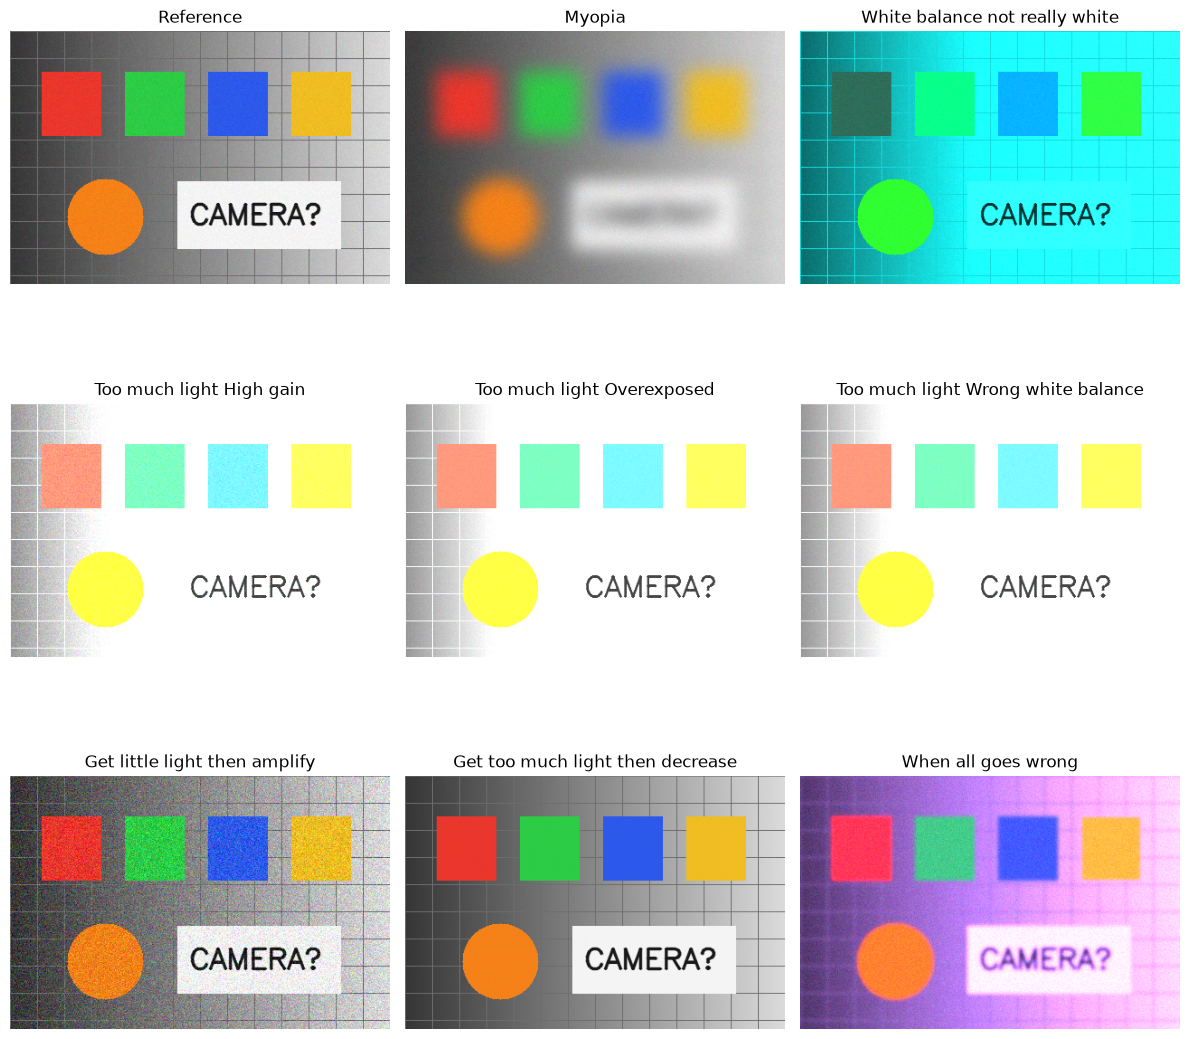

In [45]:
camera_failures = {
    "Reference": dict(),
    "Myopia": dict(focus_sigma=10),
    "White balance not really white": dict(white_balance=(0.2, 2, 2)),
    "Too much light High gain": dict(gain=2.8),
    "Too much light Overexposed": dict(exposure=2.8),
    "Too much light Wrong white balance": dict(white_balance=(2.8, 2.8, 2.8)),
    "Get little light then amplify": dict(gain=5, exposure=0.2),
    "Get too much light then decrease": dict(gain=0.2, exposure=5),
    "When all goes wrong": dict(gain=2., exposure=0.5, white_balance=(1.5, 1, 2), focus_sigma=2)
}

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (name, parameters) in zip(axes.flat, camera_failures.items()):
    result = simulate_camera(scene, **parameters)
    ax.imshow(result)
    ax.set_title(name)
    ax.axis("off")
axes.flat[-1].axis("off")
plt.tight_layout()

Might it be the answer?

If oranges for [notebook 1](./01_color_detection_pipeline.ipynb) see that stuff fixed color thresholding fails first; morphology and connected components then inherit the damaged mask.

## 5. Rolling shutter: different rows, different moments

A global shutter captures the whole frame at essentially one moment. A rolling shutter reads rows sequentially. If the scene or camera moves during that scan, the bottom rows observe a later position than the top rows, so vertical objects can lean or wobble.

The simulation below shifts each row progressively. It is not a complete sensor model, but it isolates the geometric symptom.

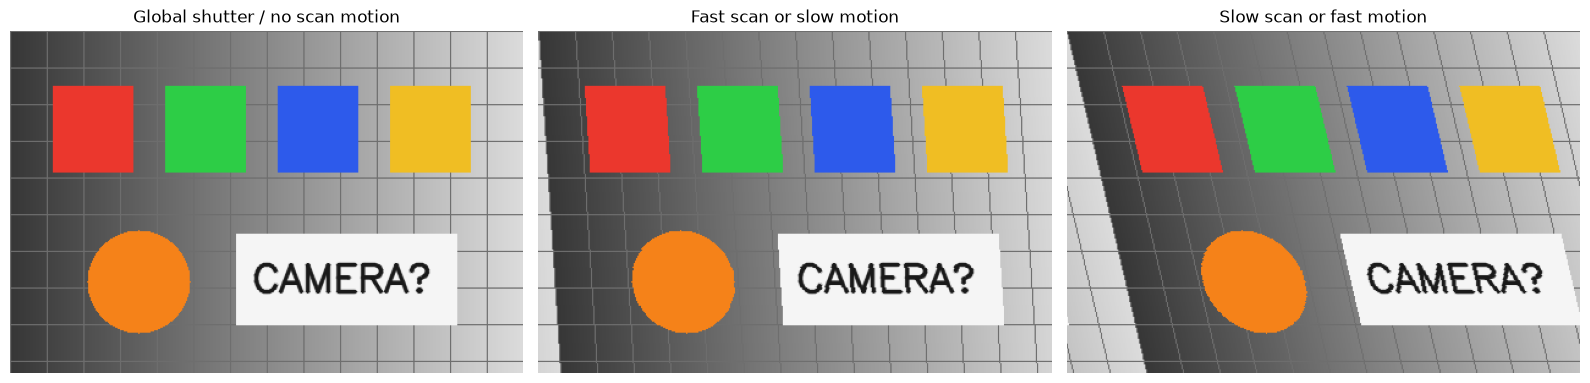

In [46]:
def rolling_shutter(rgb, total_shift):
    distorted = np.empty_like(rgb)
    for row in range(rgb.shape[0]):
        shift = round(total_shift * row / max(1, rgb.shape[0] - 1))
        distorted[row] = np.roll(rgb[row], shift, axis=0)
    return distorted

shutter_examples = {
    "Global shutter / no scan motion": scene,
    "Fast scan or slow motion": rolling_shutter(scene, 18),
    "Slow scan or fast motion": rolling_shutter(scene, 65),
}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, image) in zip(axes, shutter_examples.items()):
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()

## 6. The pinhole model: where does a 3D point land?

Ignoring distortion, a camera projects a 3D point `(X, Y, Z)` in camera coordinates to image coordinates:

`u = fx · X / Z + cx` and `v = fy · Y / Z + cy`

`fx` and `fy` are focal lengths measured in pixels. `(cx, cy)` is the principal point, usually near the image center. These values form the camera's **intrinsic matrix** `K`. The division by `Z` explains why distant objects look smaller.

> **For readers who enjoy feeding formulas after midnight:** OpenCV's [Camera Calibration and 3D Reconstruction reference](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html) develops the full pinhole projection, intrinsic matrix, world-to-camera transformation, distortion model, and camera characteristics such as field of view.

Intrinsic matrix K:
 [[520.   0. 320.]
 [  0. 520. 240.]
 [  0.   0.   1.]]


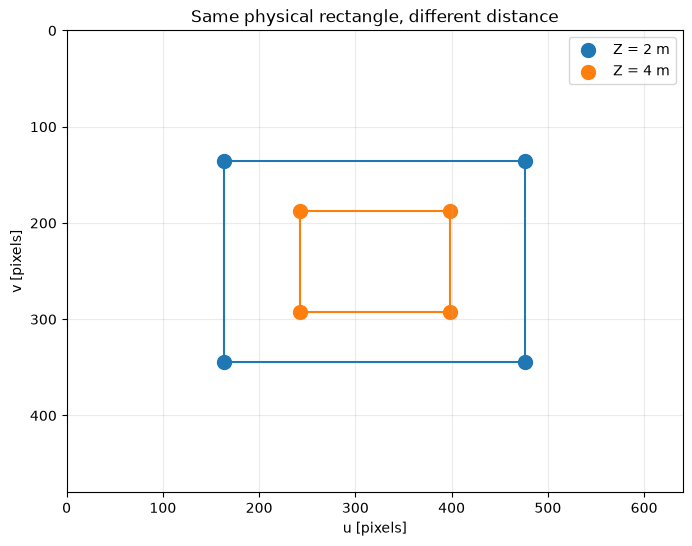

In [49]:
image_width, image_height = 640, 480
fx = fy = 520.0
cx, cy = image_width / 2, image_height / 2
K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]])
print("Intrinsic matrix K:\n", K)

def project_points(points_xyz, camera_matrix):
    normalized = points_xyz[:, :2] / points_xyz[:, 2:3]
    pixels = normalized * np.array([camera_matrix[0, 0], camera_matrix[1, 1]])
    return pixels + np.array([camera_matrix[0, 2], camera_matrix[1, 2]])

world_points = np.array([
    [-0.6, -0.4, 2.0], [0.6, -0.4, 2.0], [0.6, 0.4, 2.0], [-0.6, 0.4, 2.0],
    [-0.6, -0.4, 4.0], [0.6, -0.4, 4.0], [0.6, 0.4, 4.0], [-0.6, 0.4, 4.0],
])
pixels = project_points(world_points, K)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pixels[:4, 0], pixels[:4, 1], s=100, label="Z = 2 m")
ax.scatter(pixels[4:, 0], pixels[4:, 1], s=100, label="Z = 4 m")
for group in (pixels[:4], pixels[4:]):
    closed = np.vstack([group, group[0]])
    ax.plot(closed[:, 0], closed[:, 1])
ax.set_xlim(0, image_width)
ax.set_ylim(image_height, 0)
ax.set_aspect("equal")
ax.set_xlabel("u [pixels]")
ax.set_ylabel("v [pixels]")
ax.set_title("Same physical rectangle, different distance")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

### Focal length and field of view

For a fixed sensor size, shorter focal length gives a wider field of view; longer focal length gives a narrower, more magnified view. In pixel units, horizontal field of view is approximately `2 · atan(image_width / (2 · fx))`. Wide-angle coverage is useful, but strong lenses often bring stronger distortion and uneven effective detail across the image.

> **Further reading — provided mainly for comfort through its mere existence:** OpenCV's [`cv2.calibrationMatrixValues`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html) computes horizontal and vertical field of view, focal length, principal point, and aspect ratio from a calibrated camera matrix.

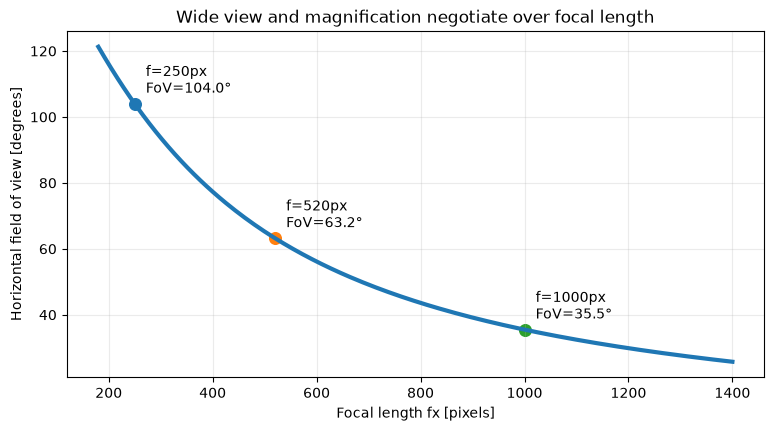

In [50]:
focal_lengths = np.linspace(180, 1400, 200)
horizontal_fov = np.degrees(2 * np.arctan(image_width / (2 * focal_lengths)))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(focal_lengths, horizontal_fov, linewidth=3)
for focal in (250, 520, 1000):
    angle = np.degrees(2 * np.arctan(image_width / (2 * focal)))
    ax.scatter(focal, angle, s=70)
    ax.annotate(f"f={focal}px\nFoV={angle:.1f}°", (focal, angle), xytext=(8, 8), textcoords="offset points")
ax.set_xlabel("Focal length fx [pixels]")
ax.set_ylabel("Horizontal field of view [degrees]")
ax.set_title("Wide view and magnification negotiate over focal length")
ax.grid(alpha=0.25)
plt.show()

## 7. Lens distortion: straight lines file a complaint

A simple radial model scales a normalized point `(x, y)` according to its radius from the optical center:

`x_distorted = x · (1 + k1 · r²)` and `y_distorted = y · (1 + k1 · r²)`

Real calibration models include more coefficients, but this single parameter is enough to see why distortion grows toward image edges. Calibration estimates both the intrinsic matrix and distortion coefficients from known geometry such as a checkerboard.

> **Deeper rabbit hole:** OpenCV's practical [Python camera-calibration tutorial](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html) explains radial and tangential distortion and estimates the coefficients from checkerboard images. The [full calib3d reference](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html) documents the larger distortion model used by OpenCV.

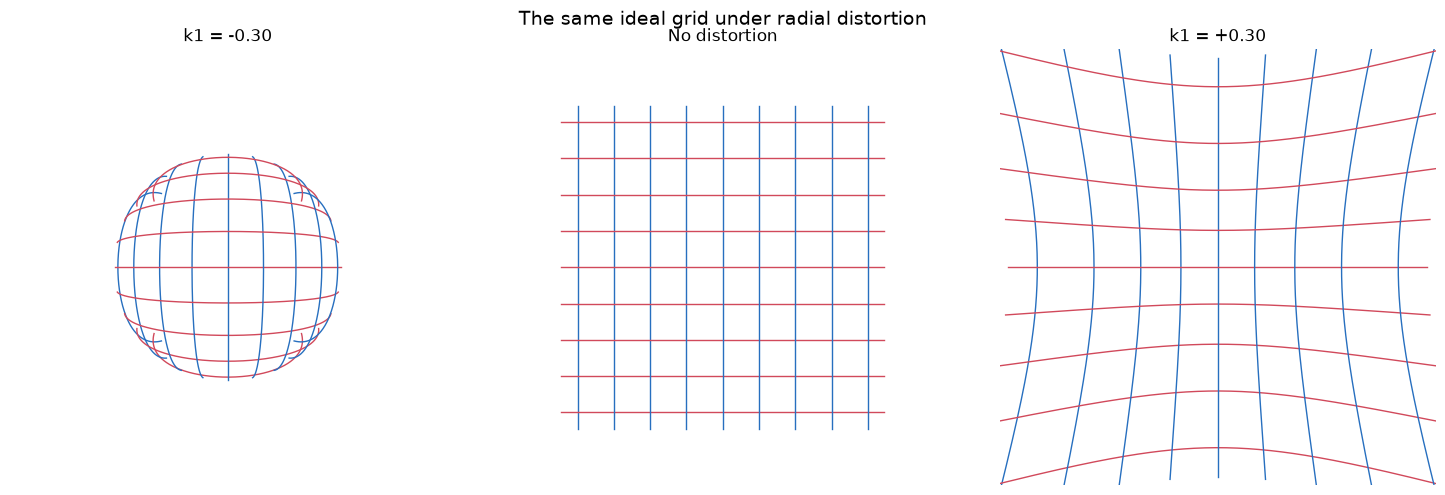

In [67]:
def radial_distort(x, y, k1):
    radius_squared = x**2 + y**2
    scale = 1 + k1 * radius_squared
    return x * scale, y * scale

line_positions = np.linspace(-0.9, 0.9, 9)
line_coordinate = np.linspace(-1.0, 1.0, 300)
distortions = {"k1 = -0.30": -0.30, "No distortion": 0.0, "k1 = +0.30": 0.30}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (title, k1) in zip(axes, distortions.items()):
    for fixed in line_positions:
        x_d, y_d = radial_distort(np.full_like(line_coordinate, fixed), line_coordinate, k1)
        ax.plot(x_d, y_d, color="#276FBF", linewidth=1)
        x_d, y_d = radial_distort(line_coordinate, np.full_like(line_coordinate, fixed), k1)
        ax.plot(x_d, y_d, color="#D1495B", linewidth=1)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.axis("off")
fig.suptitle("The same ideal grid under radial distortion", fontsize=14)
plt.tight_layout()

### Practice: bend reality responsibly

Try `k1` values beyond ±0.30 and add a second radial term `k2 · r⁴`. Observe where changes first become visible. Then extend your practice function with a movable distortion center such as `(0.35, -0.20)`. Subtract that center before computing `r²`, distort the resulting offset, and finally add the center back. The × in the practice plot marks the point around which the grid bends—a useful reminder that the principal point is a calibration parameter, not a sacred image-center guarantee.

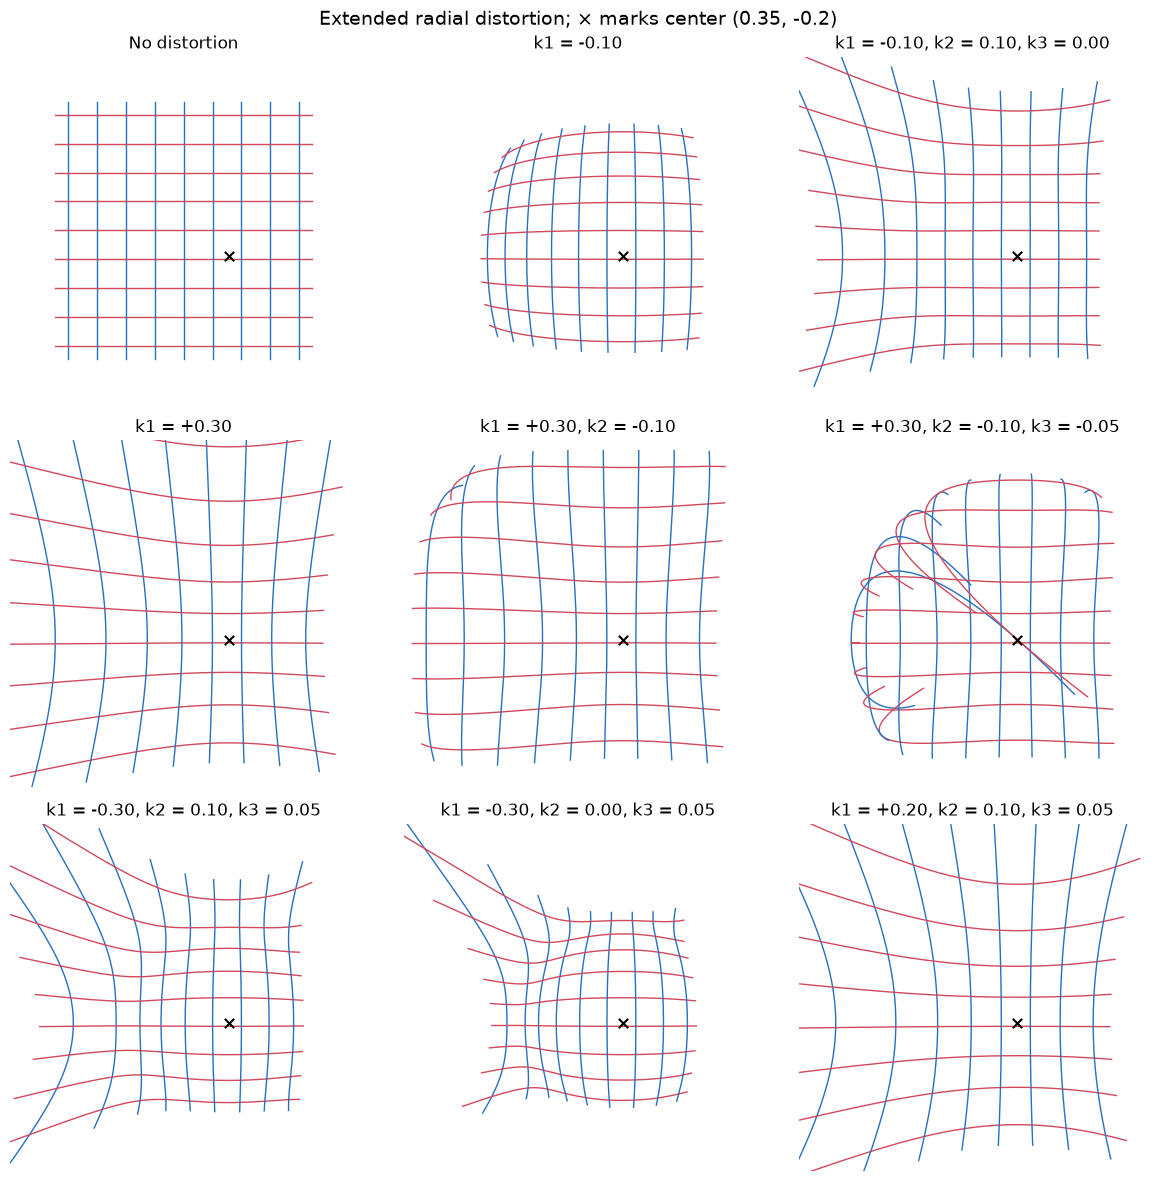

In [68]:
def radial_distort_ext(x, y, k1, k2=0.0, k3=0.0, center=(0.0, 0.0)):
    cx, cy = center
    x_from_center = x - cx
    y_from_center = y - cy
    radius_squared = x_from_center**2 + y_from_center**2
    scale = 1 + k1 * radius_squared + k2 * radius_squared**2 + k3 * radius_squared**3
    return cx + x_from_center * scale, cy + y_from_center * scale

line_positions = np.linspace(-0.9, 0.9, 9)
line_coordinate = np.linspace(-1.0, 1.0, 300)
distortion_center = (0.35, -0.20)  # Compare with (0.0, 0.0)
distortions =  {
    "No distortion": (0.00, 0.00, 0.00),
    "k1 = -0.10": (-0.10, 0.00, 0.00),
    "k1 = -0.10, k2 = 0.10, k3 = 0.00": (-0.10, 0.10, 0.00),
    "k1 = +0.30": (0.30, 0.00, 0.00),
    "k1 = +0.30, k2 = -0.10": (0.30, -0.10, 0.00),
    "k1 = +0.30, k2 = -0.10, k3 = -0.05": (0.30, -0.10, -0.05),
    "k1 = -0.30, k2 = 0.10, k3 = 0.05": (-0.30, 0.10, 0.05),
    "k1 = -0.30, k2 = 0.00, k3 = 0.05": (-0.30, 0.00, 0.05),
    "k1 = +0.20, k2 = 0.10, k3 = 0.05": (+0.20, 0.10, 0.05),
}

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (title, (k1, k2, k3)) in zip(axes.flatten(), distortions.items()):
    for fixed in line_positions:
        x_d, y_d = radial_distort_ext(np.full_like(line_coordinate, fixed), line_coordinate, k1, k2, k3, distortion_center)
        ax.plot(x_d, y_d, color="#276FBF", linewidth=1)
        x_d, y_d = radial_distort_ext(line_coordinate, np.full_like(line_coordinate, fixed), k1, k2, k3, distortion_center)
        ax.plot(x_d, y_d, color="#D1495B", linewidth=1)
    ax.scatter(*distortion_center, color="black", marker="x", s=45, zorder=3)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.axis("off")
fig.suptitle(f"Extended radial distortion; × marks center {distortion_center}", fontsize=14)
plt.tight_layout()

## 8. Distance from apparent size

If an object's real height `H` and the calibrated focal length `fy` are known, its measured pixel height `h` gives approximately:

`distance Z = fy · H / h`

This is the same pinhole relationship rearranged. Without known object size, another depth cue, or additional assumptions, one image generally cannot distinguish a small nearby object from a large distant one.

 true Z | measured height | estimated Z
   0.50 m |      420 px      |   0.50 m
   2.02 m |      104 px      |   2.02 m
   4.01 m |       52 px      |   4.04 m
   6.01 m |       35 px      |   6.00 m
   8.00 m |       26 px      |   8.08 m


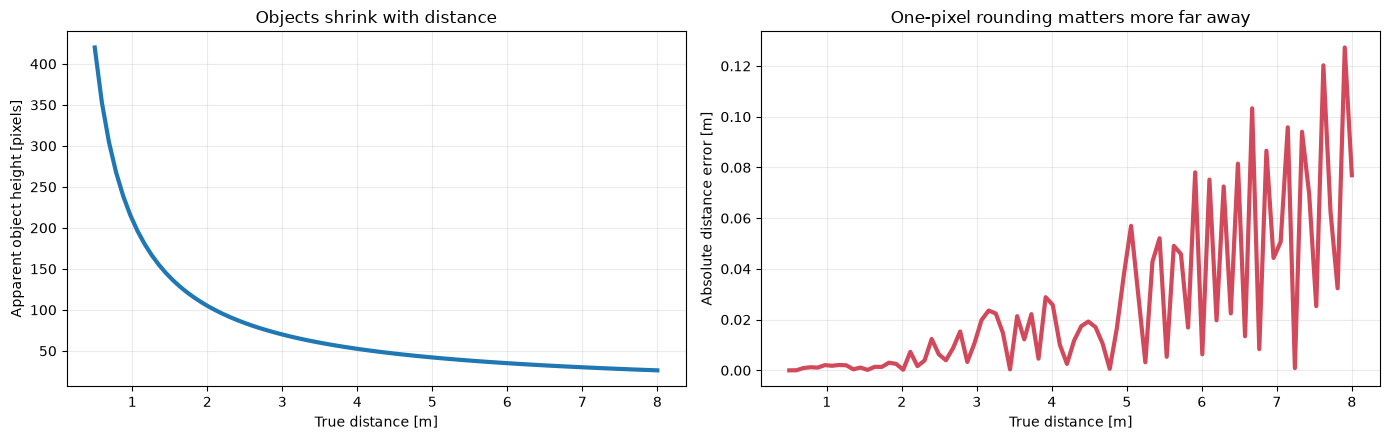

In [88]:
known_height_m = 0.30
focal_length_px = 700.0
true_distances = np.linspace(0.5, 8.0, 80)
ideal_pixel_heights = focal_length_px * known_height_m / true_distances
measured_pixel_heights = np.maximum(1, np.round(ideal_pixel_heights))
estimated_distances = focal_length_px * known_height_m / measured_pixel_heights
absolute_error = np.abs(estimated_distances - true_distances)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(true_distances, ideal_pixel_heights, linewidth=3)
axes[0].set_xlabel("True distance [m]")
axes[0].set_ylabel("Apparent object height [pixels]")
axes[0].set_title("Objects shrink with distance")

axes[1].plot(true_distances, absolute_error, color="#D1495B", linewidth=3)
axes[1].set_xlabel("True distance [m]")
axes[1].set_ylabel("Absolute distance error [m]")
axes[1].set_title("One-pixel rounding matters more far away")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()

sample_indices = [0, 16, 37, 58, 79]
print(" true Z | measured height | estimated Z")
for index in sample_indices:
    print(f" {true_distances[index]:6.2f} m | {measured_pixel_heights[index]:8.0f} px      | {estimated_distances[index]:6.2f} m")

### Practice: operate a suspicious measuring tape

Change the known object height, focal length, and pixel rounding. Add ±1 pixel of random measurement noise. Which matters more: a one-pixel mistake at 1 meter or at 8 meters? Explain the plot rather than trusting the formula's confident expression.

 true Z | measured height | estimated Z
   0.50 m |      601 px      |   0.50 m
   3.00 m |      101 px      |   2.97 m
   5.50 m |       56 px      |   5.36 m
   8.00 m |       39 px      |   7.69 m
  10.50 m |       30 px      |  10.00 m
  13.00 m |       25 px      |  12.00 m
  15.50 m |       21 px      |  14.29 m
  18.00 m |       18 px      |  16.67 m
  20.50 m |       16 px      |  18.75 m
  23.00 m |       15 px      |  20.00 m
  25.50 m |       13 px      |  23.08 m
  28.00 m |       12 px      |  25.00 m
  30.50 m |       11 px      |  27.27 m
  33.00 m |       11 px      |  27.27 m
  35.50 m |       10 px      |  30.00 m
  38.00 m |        9 px      |  33.33 m
  40.50 m |        9 px      |  33.33 m
  43.00 m |        8 px      |  37.50 m
  45.50 m |        8 px      |  37.50 m
  48.00 m |        8 px      |  37.50 m


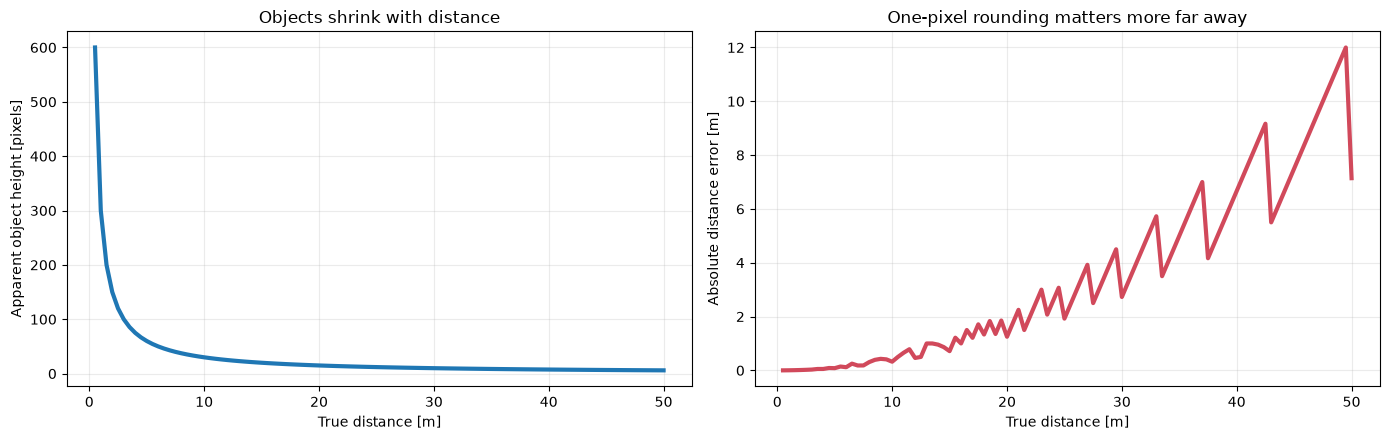

In [92]:
known_height_m = 0.60
focal_length_px = 500.0
true_distances = np.linspace(0.5, 50, 100)
ideal_pixel_heights = focal_length_px * known_height_m / true_distances
measured_pixel_heights = np.maximum(1, np.ceil(ideal_pixel_heights)) + 1
estimated_distances = focal_length_px * known_height_m / measured_pixel_heights
absolute_error = np.abs(estimated_distances - true_distances)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(true_distances, ideal_pixel_heights, linewidth=3)
axes[0].set_xlabel("True distance [m]")
axes[0].set_ylabel("Apparent object height [pixels]")
axes[0].set_title("Objects shrink with distance")

axes[1].plot(true_distances, absolute_error, color="#D1495B", linewidth=3)
axes[1].set_xlabel("True distance [m]")
axes[1].set_ylabel("Absolute distance error [m]")
axes[1].set_title("One-pixel rounding matters more far away")
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()

sample_indices = range(0, 100, 5)
print(" true Z | measured height | estimated Z")
for index in sample_indices:
    print(f" {true_distances[index]:6.2f} m | {measured_pixel_heights[index]:8.0f} px      | {estimated_distances[index]:6.2f} m")

#### Controlled sensitivity experiment

The next cell freezes one set of measured pixel heights. The first two plots then change only the value *assumed by the estimator*: focal length or known object height. This represents incorrect calibration or an incorrect size assumption. The last two plots keep both values correct and isolate a `+1 px` or `-1 px` measurement mistake.

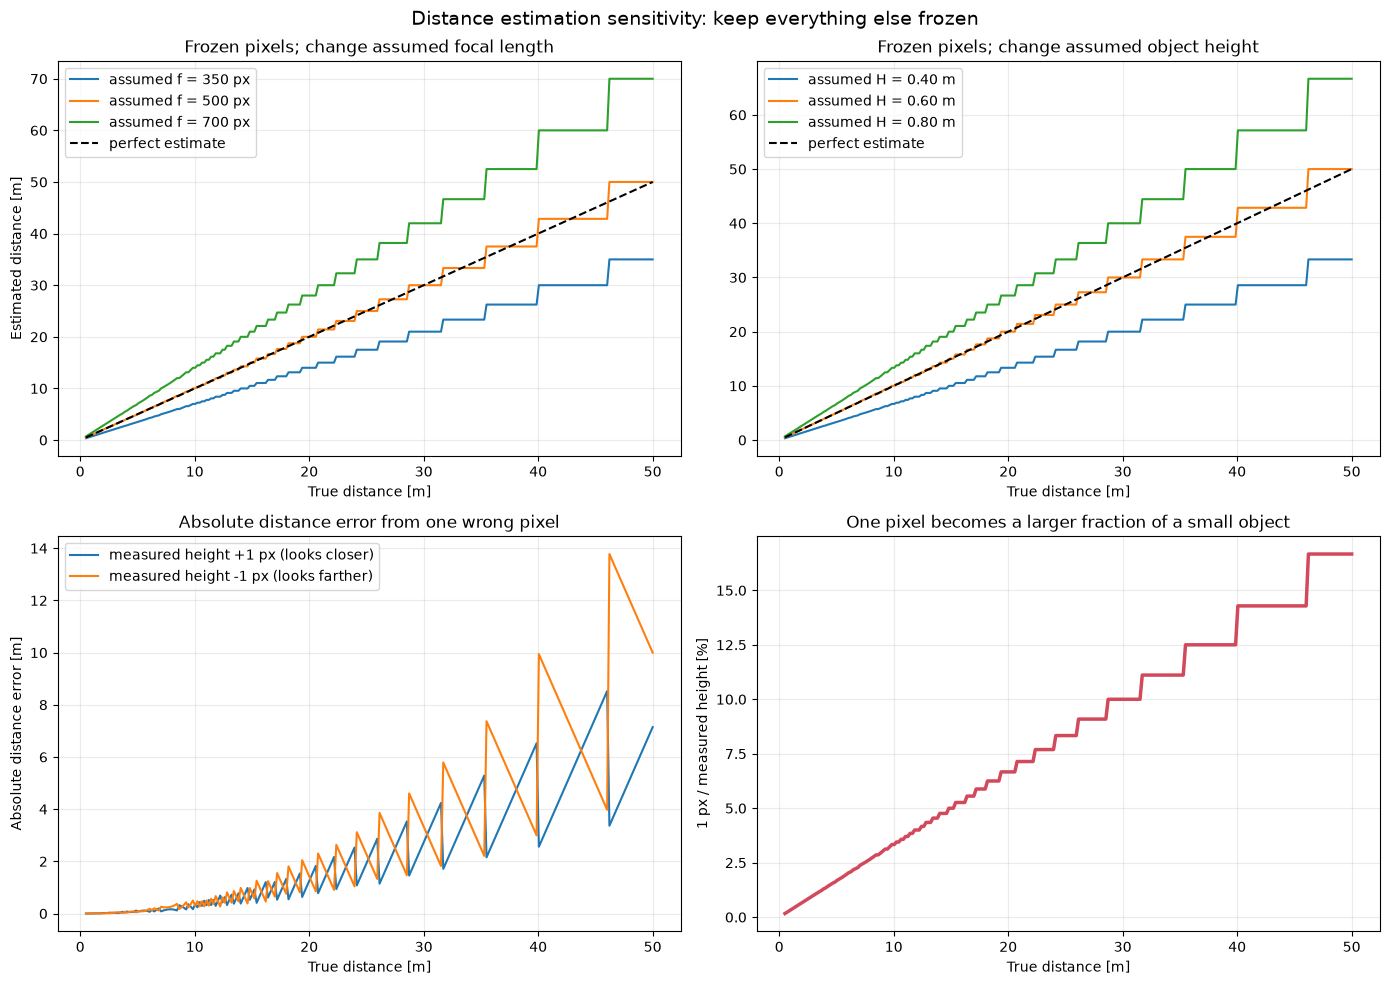

In [93]:
true_focal_length_px = 500.0
true_object_height_m = 0.60
true_distances = np.linspace(0.5, 50.0, 250)

# Generate one frozen set of integer pixel measurements with the true camera/object values.
ideal_heights_px = true_focal_length_px * true_object_height_m / true_distances
frozen_heights_px = np.maximum(1, np.round(ideal_heights_px))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Same measurements and object size; only the assumed focal length changes.
for assumed_focal_length in (350.0, 500.0, 700.0):
    estimates = assumed_focal_length * true_object_height_m / frozen_heights_px
    axes[0, 0].plot(true_distances, estimates, label=f"assumed f = {assumed_focal_length:.0f} px")
axes[0, 0].plot(true_distances, true_distances, "k--", label="perfect estimate")
axes[0, 0].set_title("Frozen pixels; change assumed focal length")
axes[0, 0].set_ylabel("Estimated distance [m]")
axes[0, 0].legend()

# 2. Same measurements and focal length; only the assumed real object height changes.
for assumed_height in (0.40, 0.60, 0.80):
    estimates = true_focal_length_px * assumed_height / frozen_heights_px
    axes[0, 1].plot(true_distances, estimates, label=f"assumed H = {assumed_height:.2f} m")
axes[0, 1].plot(true_distances, true_distances, "k--", label="perfect estimate")
axes[0, 1].set_title("Frozen pixels; change assumed object height")
axes[0, 1].legend()

# 3. Correct calibration and object size; change only the measured height by one pixel.
height_plus_one = frozen_heights_px + 1
height_minus_one = np.maximum(1, frozen_heights_px - 1)
estimate_plus_one = true_focal_length_px * true_object_height_m / height_plus_one
estimate_minus_one = true_focal_length_px * true_object_height_m / height_minus_one
axes[1, 0].plot(true_distances, np.abs(estimate_plus_one - true_distances), label="measured height +1 px (looks closer)")
axes[1, 0].plot(true_distances, np.abs(estimate_minus_one - true_distances), label="measured height -1 px (looks farther)")
axes[1, 0].set_title("Absolute distance error from one wrong pixel")
axes[1, 0].set_ylabel("Absolute distance error [m]")
axes[1, 0].legend()

# 4. Why the same one pixel matters more far away.
one_pixel_percent = 100 / frozen_heights_px
axes[1, 1].plot(true_distances, one_pixel_percent, color="#D1495B", linewidth=2.5)
axes[1, 1].set_title("One pixel becomes a larger fraction of a small object")
axes[1, 1].set_ylabel("1 px / measured height [%]")

for ax in axes.flat:
    ax.set_xlabel("True distance [m]")
    ax.grid(alpha=0.25)

fig.suptitle("Distance estimation sensitivity: keep everything else frozen", fontsize=14)
plt.tight_layout()
plt.show()

### Quick reflection

- Why can increasing resolution fail to reveal more real detail?
- Why might automatic exposure or white balance break a fixed classical-CV threshold?
- What visual symptom separates rolling-shutter distortion from ordinary motion blur?
- Which calibrated quantities are required for size-based distance estimation?
- Why is distance error more sensitive to pixel measurement when the object is far away?

## Takeaway

A camera contributes assumptions before our vision algorithm reads its first pixel:

1. the sensor samples color and space imperfectly;
2. resolution and FPS compete for bandwidth and computation;
3. automatic settings can change the data distribution between frames;
4. shutter timing can deform moving scenes;
5. intrinsics project 3D geometry into pixels;
6. lenses distort that projection;
7. calibration turns those effects from surprises into measurable parameters.

The camera is not merely where images come from. It is the first algorithm in the pipeline, except it arrives wearing hardware.